# CaSR and HRDPS Variable Swap Results

We have CaSR wind, CaSR solar and CaSR heat(longwave+humidity+temperature) swapped in HRDPS forcing fields. This comparison shall help us to identify which variables are driving the biological responses.


## Visualization

In [1]:
# paths
# Example: "/ocean/jqiu/results/Flux/flux_00mar23_hrdps2.5/" + "SalishSea_1d_20230301_20230331_grid_T.nc"

EXPERIMENTS_head = {
    "HRDPS2.5": {
        "Mar": (
            "/ocean/jqiu/results/Flux/flux_00mar23_hrdps2.5/"
            "SalishSea_1d_20230301_20230331"
        ),
        "Jun": (
                    "/ocean/jqiu/results/Flux/flux_00jun23_hrdps2.5/" # Not available yet
                    "SalishSea_1d_20230601_20230630"
        ),
        "Sep": (
                    "/ocean/jqiu/results/Flux/flux_00sep23_hrdps2.5/" # Not available yet
                    "SalishSea_1d_20230901_20230930"
        ),
        "Dec": (
                    "/ocean/jqiu/results/Flux/flux_00dec23_hrdps2.5/" # Not available yet
                    "SalishSea_1d_20231201_20231231"
        ),
    },
    "CaSR": {
        "Mar": (
            "/ocean/jqiu/results/Flux/flux_00mar23_CaSR/"
            "SalishSea_1d_20230301_20230331"
        ),
        "Jun": (
                    "/ocean/jqiu/results/Flux/flux_00jun23_CaSR/" 
                    "SalishSea_1d_20230601_20230630"
        ),
        "Sep": (
                    "/ocean/jqiu/results/Flux/flux_00sep23_CaSR/" 
                    "SalishSea_1d_20230901_20230930"
        ),
        "Dec": (
                    "/ocean/jqiu/results/Flux/flux_00dec23_CaSR/" 
                    "SalishSea_1d_20231201_20231231"
        ),
    },
    "HRDPS2.5+CaSR_wind": {
            "Mar": (
                "/ocean/jqiu/results/Sensivity/CaSR_wind_HRDPS_else/"
                "SalishSea_1d_20230301_20230331"
        ),
    },
    "HRDPS2.5+CaSR_solar": {
            "Mar": (
                "/ocean/jqiu/results/Sensivity/CaSR_solar_HRDPS_else/"
                "SalishSea_1d_20230301_20230331"
        ),
    },
    "HRDPS2.5+CaSR_heat": {
            "Mar": (
                "/ocean/jqiu/results/Sensivity/CaSR_heat_HRDPS_else/"
                "SalishSea_1d_20230301_20230331"
        ),
    },    
}



EXPERIMENTS_tail = {
    'Physical': '_grid_T.nc',
    'Biological': '_biol_T.nc',
    'Velocity_u': '_grid_U.nc',
    'Velocity_v': '_grid_V.nc',
    'Chemical': '_chem_T.nc'
}

# List_month={'Mar','Jun','Sep','Dec'}
List_month={'Mar'}

In [3]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

# ============================================================
# Settings
# ============================================================

BIO_VARS = ("nitrate", "diatoms", "flagellates")

REGIONS_TO_PLOT = {
    "Pam Rocks": "pam_rocks",
    "Sand Heads": "sandheads",
    "Puget Sound": "puget_sound",
}

MONTH = "Mar"
N_LEVELS = 20

SPATIAL_DIMS = ("deptht", "y", "x")

path_weights = Path(
    "/home/jqiu/analysis-junqi/"
    "Analysis_Atmospheric_Forcing/"
    "Analysis_results_comparison/"
    "Analysis_sensitivity/Weights_Area/"
)

EXPERIMENT_COLORS = {
    "HRDPS2.5": "tab:blue",
    "CaSR": "tab:green",
    "HRDPS2.5+CaSR_wind": "tab:purple",
    "HRDPS2.5+CaSR_solar": "tab:orange",
    "HRDPS2.5+CaSR_heat": "tab:red",
}

VAR_LABELS = {
    "nitrate": "Nitrate",
    "diatoms": "Diatoms",
    "flagellates": "Flagellates",
}



Pam Rocks      : Top 20 layers weights sum = 1.000000
Sand Heads     : Top 20 layers weights sum = 1.000000
Puget Sound    : Top 20 layers weights sum = 1.000000

Processing experiment: HRDPS2.5
  Finished: nitrate
  Finished: diatoms
  Finished: flagellates

Processing experiment: CaSR
  Finished: nitrate
  Finished: diatoms
  Finished: flagellates

Processing experiment: HRDPS2.5+CaSR_wind
  Finished: nitrate
  Finished: diatoms
  Finished: flagellates

Processing experiment: HRDPS2.5+CaSR_solar
  Finished: nitrate
  Finished: diatoms
  Finished: flagellates

Processing experiment: HRDPS2.5+CaSR_heat
  Finished: nitrate
  Finished: diatoms
  Finished: flagellates


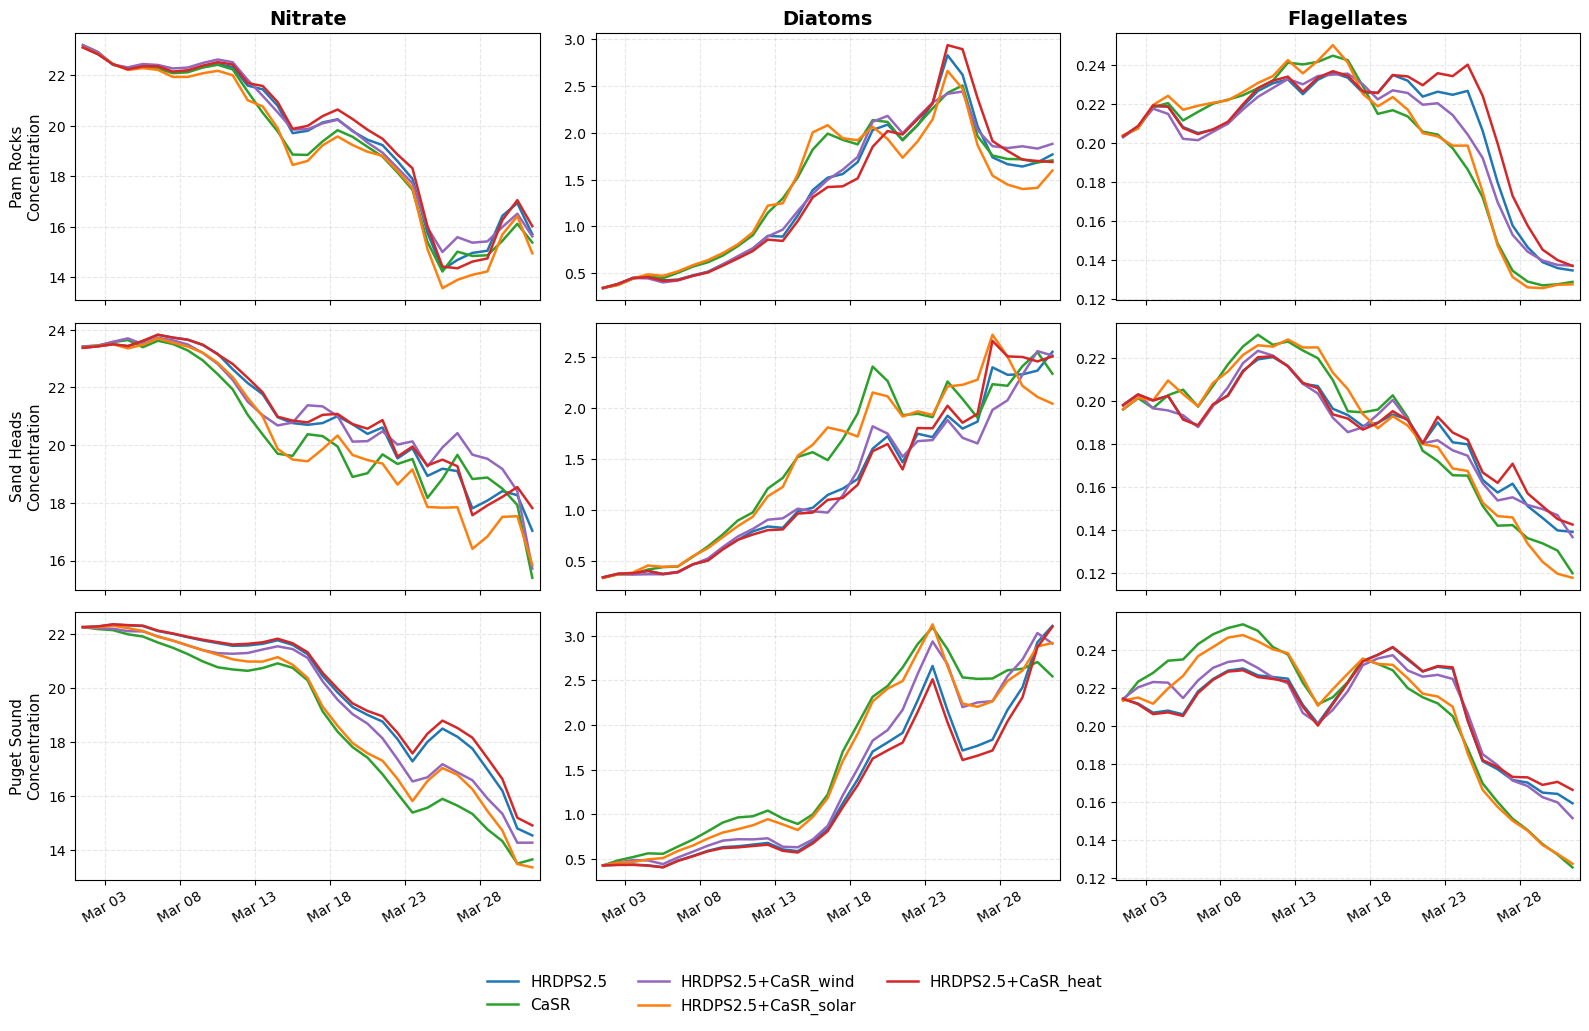

In [4]:

# Load weights (Top 20 layers)


region_weights = {}

for region_name, region_file in REGIONS_TO_PLOT.items():

    weight_file = path_weights / f"{region_file}_weights.nc"

    with xr.open_dataset(weight_file) as ds_w:

        # Select top 20 layers
        weights = ds_w["weights"].isel(
            deptht=slice(0, N_LEVELS)
        ).load()

    # Renormalize weights for top 20 layers
    weights = weights / weights.sum(
        dim=("deptht", "y", "x")
    )

    region_weights[region_name] = weights

    print(
        f"{region_name:15s}: "
        f"Top {N_LEVELS} layers weights sum = "
        f"{weights.sum().item():.6f}"
    )



# Calculate regional means


# Structure:
# results[region][variable][experiment] = DataArray(time_counter)

results = {
    region: {var: {} for var in BIO_VARS}
    for region in REGIONS_TO_PLOT
}

spatial_dims = ("deptht", "y", "x")

for exp_name, exp_paths in EXPERIMENTS_head.items():

    if MONTH not in exp_paths:
        continue

    file_path = (
        exp_paths[MONTH]
        + EXPERIMENTS_tail["Biological"]
    )

    if not Path(file_path).exists():
        print(f"File not found: {file_path}")
        continue

    print(f"\nProcessing experiment: {exp_name}")

    with xr.open_dataset(
        file_path,
        chunks={"time_counter": 1}
    ) as ds:

        for var_name in BIO_VARS:

            if var_name not in ds:
                print(f"  Variable not found: {var_name}")
                continue

            # Select top 20 layers
            var = ds[var_name].isel(
                deptht=slice(0, N_LEVELS)
            )

            for region_name, weights in region_weights.items():

                # Volume-weighted mean
                # Renormalize for any missing values

                numerator = (var * weights).sum(
                    dim=spatial_dims
                )

                denominator = weights.where(
                    var.notnull()
                ).sum(dim=spatial_dims)

                regional_mean = numerator / denominator

                # Load only the reduced time series
                results[region_name][var_name][exp_name] = (
                    regional_mean.load()
                )

            print(f"  Finished: {var_name}")



# Visualize


fig, axes = plt.subplots(
    nrows=3,
    ncols=3,
    figsize=(16, 11),
    sharex=True
)

regions = list(REGIONS_TO_PLOT.keys())

var_labels = {
    "nitrate": "Nitrate",
    "diatoms": "Diatoms",
    "flagellates": "Flagellates",
}

for i, region_name in enumerate(regions):

    for j, var_name in enumerate(BIO_VARS):

        ax = axes[i, j]

        for exp_name, ts in results[region_name][var_name].items():

            ax.plot(
                ts["time_counter"].values,
                ts.values,
                label=exp_name,
                color=EXPERIMENT_COLORS.get(exp_name),
                linewidth=1.8,
            )

        if i == 0:
            ax.set_title(
                var_labels[var_name],
                fontsize=14,
                fontweight="bold"
            )

        if j == 0:
            ax.set_ylabel(
                f"{region_name}\nConcentration",
                fontsize=11
            )

        ax.grid(alpha=0.3, linestyle="--")

        ax.xaxis.set_major_locator(
            mdates.DayLocator(interval=5)
        )

        ax.xaxis.set_major_formatter(
            mdates.DateFormatter("%b %d")
        )

        ax.tick_params(axis="x", rotation=30)

        ax.set_xlim(
            np.datetime64("2023-03-01"),
            np.datetime64("2023-04-01")
        )



# Legend and layout


handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=3,
    frameon=False,
    fontsize=11
)

plt.tight_layout(rect=[0, 0.09, 1, 0.95])

plt.show()

`CaSR` **heat** is ordinary. `CaSR` **solar** is the main driver of the bio-response. `CaSR` **wind** amplified the bio-response at Puget Sound and Sandheads (surprisingly), but the amplification is not significant at Pam Rocks.